# 00 – EDA – Mission: Flying SPAGHETTI

Goal of this notebook: **understand the data before training any model**.

The organisers warned us about two things:
1. *train and test may not look alike* → distribution shift;
2. *not every training entry can be trusted* → corrupted images or wrong labels.

Each section answers one precise question. At the end there is a summary with the practical consequences for training.

| # | Question |
|---|---|
| 1 | Are the files intact? How many images per class? |
| 2 | What do the images look like? |
| 3 | Are the pixel statistics (brightness, noise, colour) the same in train and test? |
| 4 | Is some artefact tied to the class? |
| 5 | What kind of shift does the test set have? |
| 6 | Embeddings from a general-purpose pretrained model |
| 7 | How many images carry the alien? And in the test? |
| 8 | UMAP: where do train and test lie in feature space? |
| 9 | Adversarial validation: how distinguishable is train from test? |
| 10 | Linear probe: first reference F1, confused classes, suspicious labels |
| 11 | Exact duplicates |
| 12 | Save the metadata for the next notebooks |

**Run order of the notebooks:** `00_eda` → `01_clean_dataset` → `02_validation_setup`. Each one reads the files written by the previous ones.

## 0. Setup
Imports, paths and a couple of helpers used throughout the notebook. Paths and class names come from `common.py`, shared by every notebook: `C.DATA` is the folder with `train/`, `test/` and `train.csv`, `C.OUT` is where we save intermediate results (caches).

In [1]:
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFilter
from tqdm.auto import tqdm

import common as C

CLASSES = C.CLASSES
OUT = C.OUT
plt.rcParams["figure.dpi"] = 90
print("DATA =", C.DATA)


def load(img_id):
    # Load an image from its id ("train_00012" or "test_00345") as an RGB uint8 array.
    return np.asarray(C.load_image(img_id))


def show_grid(ids, titles=None, ncols=8, size=1.7, suptitle=None):
    # Show a grid of images, with an optional caption above each one.
    ids = list(ids)
    nrows = int(np.ceil(len(ids) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size * 1.1))
    for ax in np.atleast_1d(axes).ravel():
        ax.axis("off")
    for i, (ax, img_id) in enumerate(zip(np.atleast_1d(axes).ravel(), ids)):
        ax.imshow(load(img_id))
        ax.set_title(titles[i] if titles is not None else img_id.split("_")[1], fontsize=7)
    if suptitle:
        fig.suptitle(suptitle)
    plt.tight_layout()
    plt.show()

DATA = /home/elia/ANN-DL-Challenge/data


## 1. File integrity and class distribution
First we check that:
- the number of files matches what was announced;
- every id in `train.csv` has its file and vice versa;
- all labels are in the range 0–9.

We build a single DataFrame `df` with **one row per image** (train + test). It is used throughout the notebook: every later analysis adds a column.

In [2]:
labels = pd.read_csv(C.DATA / "train.csv")

# sorted list of files, train first then test
rows = [{"id": p.stem, "split": s} for s in ["train", "test"] for p in sorted((C.DATA / s).glob("*.png"))]
df = pd.DataFrame(rows).merge(labels, on="id", how="left")   # label = NaN for the test set

print(df.split.value_counts().to_dict())
print("rows in train.csv:", len(labels), "| unique ids:", labels.id.nunique())
print("ids in the csv without a file:", len(set(labels.id) - set(df[df.split == "train"].id)))
print("train files without a label:", df[(df.split == "train") & df.label.isna()].shape[0])
print("label values:", sorted(labels.label.unique()))

{'test': 14736, 'train': 4328}
rows in train.csv: 4328 | unique ids: 4328
ids in the csv without a file: 0
train files without a label: 0
label values: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]


,name,n,%
0,disturbed,213,4.9
1,merging,345,8.0
2,round smooth,744,17.2
3,in-between smooth,685,15.8
4,cigar,83,1.9
5,barred spiral,584,13.5
6,tight spiral,565,13.1
7,loose spiral,477,11.0
8,edge-on no bulge,276,6.4
9,edge-on bulge,356,8.2


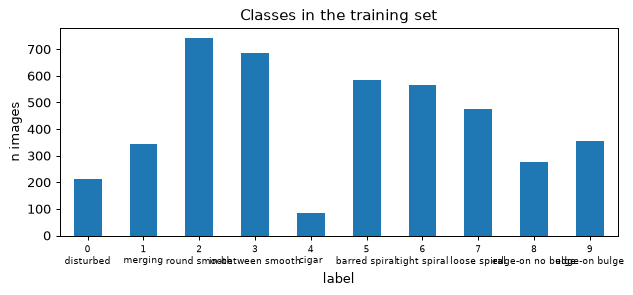

In [3]:
# class distribution in the training set
vc = labels.label.value_counts().sort_index()
tab = pd.DataFrame({"name": [CLASSES[c] for c in vc.index], "n": vc.values,
                    "%": (100 * vc / vc.sum()).round(1).values})
display(tab)

ax = vc.plot.bar(figsize=(8, 3), color="tab:blue")
ax.set_xticklabels([f"{c}\n{CLASSES[c]}" for c in vc.index], rotation=0, fontsize=7)
ax.set_ylabel("n images"); ax.set_title("Classes in the training set")
plt.show()

**What to notice.** The classes are imbalanced: class 4 (*cigar*) has very few examples compared with classes 2–3. Consequences:
- the metric is the **weighted F1**, so large classes count more, but getting class 4 completely wrong still costs something;
- validation must use a **stratified K-fold**, otherwise some folds end up with almost no *cigar*.

## 2. Looking at the images
No statistic replaces looking at the data. We show 16 random images per class, then 32 random test images.

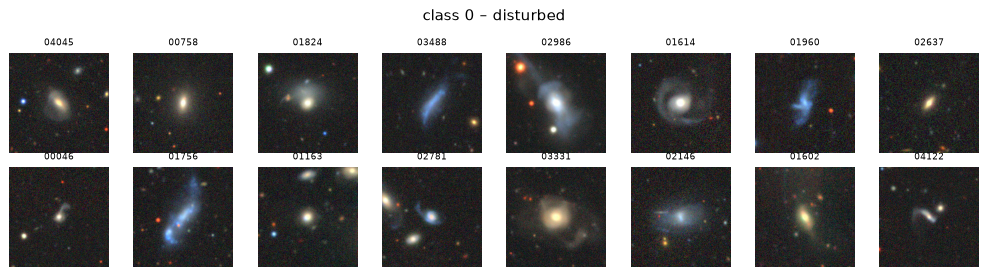

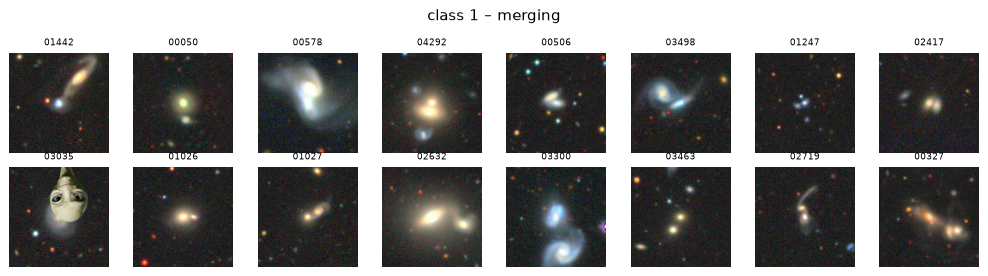

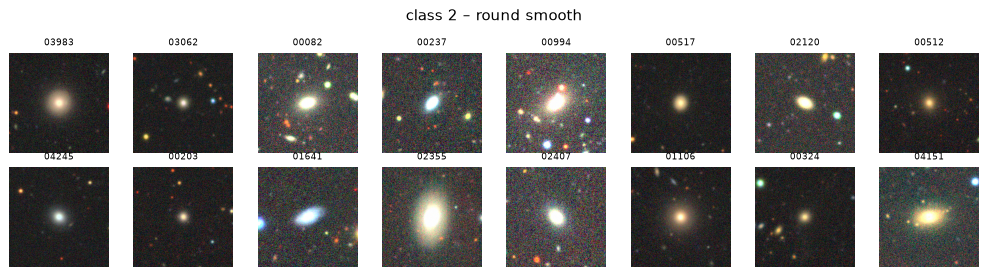

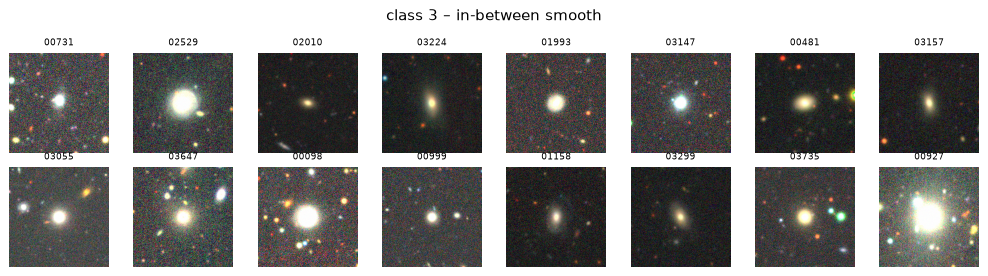

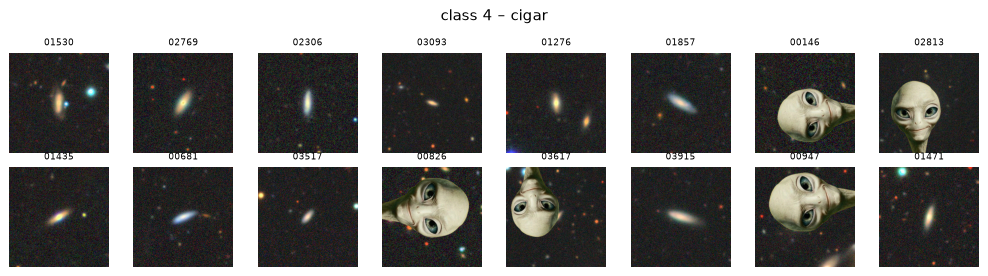

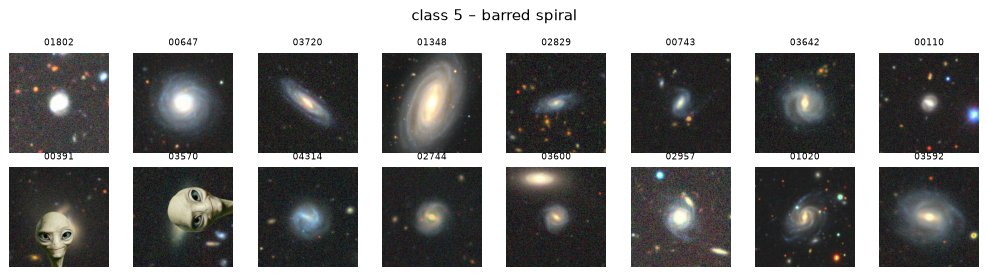

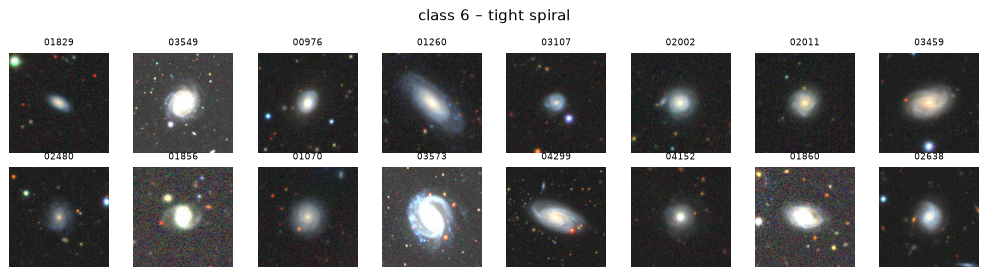

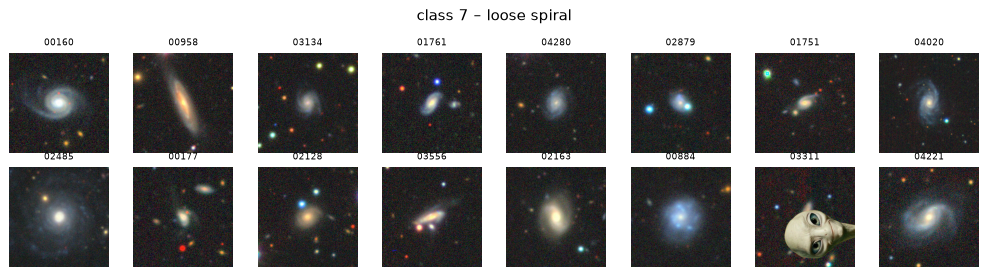

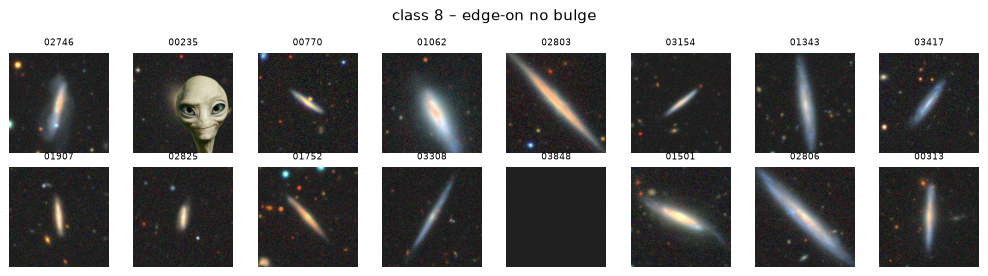

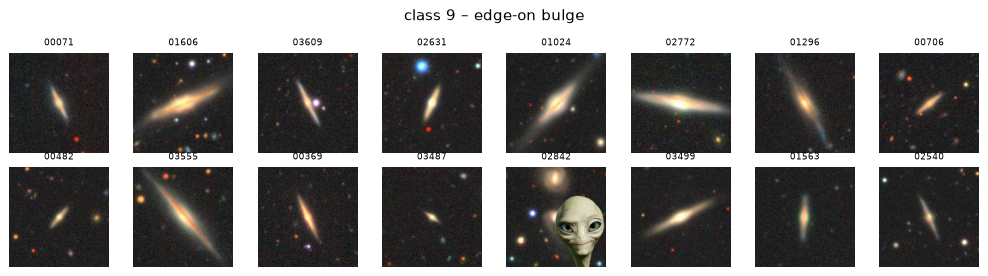

In [4]:
train = df[df.split == "train"]
for c in range(10):
    ids = train[train.label == c].sample(16, random_state=0).id
    show_grid(ids, suptitle=f"class {c} – {CLASSES[c]}", size=1.4)

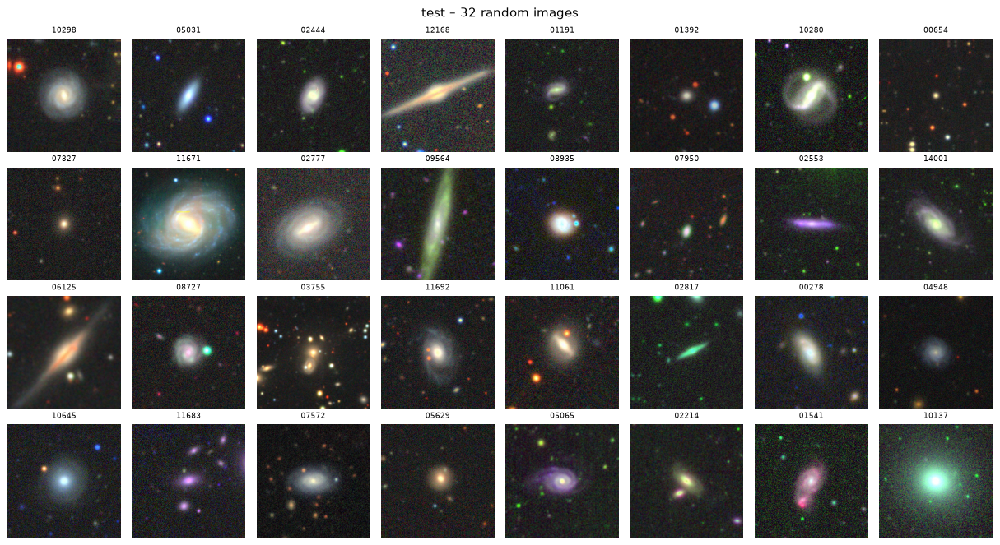

In [5]:
show_grid(df[df.split == "test"].sample(32, random_state=0).id, suptitle="test – 32 random images")

**What we see by eye.**
- **Train:** some images have an **alien face** pasted on top, in every class. Others are **brighter and grainier** than normal.
- **Test:** no aliens, but some images have **altered colours** (green, purple, pink tints) or are **blurred**.

The next sections turn these impressions into numbers.

## 3. Pixel statistics: train vs test
For every image we compute a few simple quantities:

| column | meaning |
|---|---|
| `mean`, `std` | mean brightness and contrast (all channels, 0–255) |
| `mean_r/g/b` | mean brightness of each channel |
| `chroma_r`, `chroma_g` | **chromaticity**: share of red and green over the total (R/(R+G+B), G/(R+G+B)). It depends on the colour, not on the brightness: it reveals colour casts |
| `sat` | mean saturation (S channel of the HSV space) |
| `noise` | **high-frequency noise**: median of \|gray − gray after a 3×3 median filter\|. High = grainy, close to zero = blurred |

The computation takes a few minutes, so the result is saved in `outputs/pixel_stats.csv` and reloaded the next times.

In [6]:
def pixel_stats(img_id):
    a = load(img_id).astype(np.float32)
    s = a.reshape(-1, 3).sum(1) + 1e-6                     # R+G+B per pixel
    g = Image.fromarray(load(img_id)).convert("L")
    resid = np.asarray(g, np.float32) - np.asarray(g.filter(ImageFilter.MedianFilter(3)), np.float32)
    hsv = np.asarray(Image.fromarray(load(img_id)).convert("HSV"), np.float32)
    return dict(
        mean=a.mean(), std=a.std(),
        mean_r=a[..., 0].mean(), mean_g=a[..., 1].mean(), mean_b=a[..., 2].mean(),
        chroma_r=(a[..., 0].ravel() / s).mean(), chroma_g=(a[..., 1].ravel() / s).mean(),
        sat=hsv[..., 1].mean(), noise=np.median(np.abs(resid)),
    )

cache = OUT / "pixel_stats.csv"
if cache.exists():
    stats = pd.read_csv(cache)
else:
    stats = pd.DataFrame([{"id": i, **pixel_stats(i)} for i in tqdm(df.id)])
    stats.to_csv(cache, index=False)

df = df.merge(stats, on="id")
df.groupby("split")[["mean", "std", "sat", "noise", "chroma_r", "chroma_g"]].describe().T.round(3)

  0%|          | 0/19064 [00:00<?, ?it/s]

split                test     train
mean     count  14736.000  4328.000
         mean      41.025    53.552
         std        9.193    20.845
         min       12.007    31.992
         25%       36.310    38.461
         50%       39.378    43.090
         75%       44.715    66.604
         max      194.067   180.455
std      count  14736.000  4328.000
         mean      28.311    35.896
         std        7.480    12.443
         min        3.015     3.016
         25%       23.167    26.037
         50%       27.078    31.740
         75%       32.290    44.672
         max       71.999    79.916
sat      count  14736.000  4328.000
         mean     107.178   111.955
         std       23.021    15.171
         min       34.868    35.825
         25%       92.116   103.508
         50%      107.876   113.555
         75%      122.262   122.514
         max      189.163   156.615
noise    count  14736.000  4328.000
         mean       3.879     5.775
         std        1.780     2.758
         min        1.000     1.000
         25%        3.000     4.000
         50%        4.000     5.000
         75%        5.000     7.000
         max       15.000    21.000
chroma_r count  14736.000  4328.000
         mean       0.336     0.338
         std        0.010     0.009
         min        0.184     0.276
         25%        0.331     0.333
         50%        0.337     0.338
         75%        0.342     0.343
         max        0.600     0.379
chroma_g count  14736.000  4328.000
         mean       0.334     0.337
         std        0.007     0.005
         min        0.222     0.303
         25%        0.331     0.334
         50%        0.335     0.337
         75%        0.338     0.340
         max        0.430     0.364

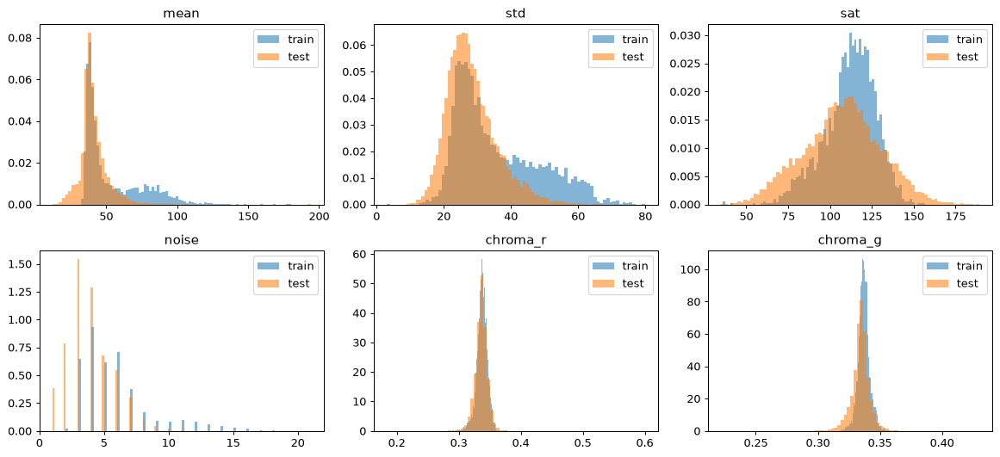

In [7]:
# overlapping histograms: if train and test came from the same distribution, the two curves would coincide.
# density=True scales each histogram to area 1, so train (4k images) and test (15k) are comparable.
cols = ["mean", "std", "sat", "noise", "chroma_r", "chroma_g"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, col in zip(axes.ravel(), cols):
    for split, c in [("train", "tab:blue"), ("test", "tab:orange")]:
        ax.hist(df[df.split == split][col], bins=80, alpha=.55, density=True, label=split, color=c)
    ax.set_title(col); ax.legend()
plt.tight_layout(); plt.show()

**How to read the plots.** x = value of the statistic for one image; y = density (how frequent that value is). The curves do not coincide, so train and test do **not** come from the same distribution:
- **`mean`, `std`:** the train set has a second group of much brighter, higher-contrast images that is almost absent from the test;
- **`noise`:** the test has a peak close to zero (blurred images) that the train lacks, while the train has a tail of very grainy images;
- **`sat`, `chroma`:** the test is more spread out, because some images have colour casts.

## 4. Is an artefact tied to the class?
If an artefact (e.g. "brightened image") appears mostly in some classes, a network can learn the shortcut *"bright ⇒ class 2"* instead of the shape of the galaxy. If the artefact is absent from the test, the shortcut is useless, and validation on the training set looks deceptively good.

We use the **99th percentile of the test** as threshold: a training image above it is "more extreme than almost all of the test". The test is used only to set this single global threshold (it has no labels); the per-class comparison is done inside the training set.

In [8]:
test = df[df.split == "test"]
thr_mean = test["mean"].quantile(0.99)
thr_noise = test["noise"].quantile(0.99)
print(f"thresholds (99th percentile of the test): mean > {thr_mean:.1f}, noise > {thr_noise:.1f}")

df["bright"] = df["mean"] > thr_mean
df["grainy"] = df["noise"] > thr_noise
train, test = df[df.split == "train"], df[df.split == "test"]

# share of 'bright' and 'grainy' images per class, in the training set
per_class = train.groupby("label")[["bright", "grainy"]].mean().mul(100).round(1)
per_class.index = [f"{int(c)} {CLASSES[int(c)]}" for c in per_class.index]
print(f"train: bright {100*train.bright.mean():.1f}%  grainy {100*train.grainy.mean():.1f}%")
print(f"test : bright {100*test.bright.mean():.1f}%  grainy {100*test.grainy.mean():.1f}%")
per_class

thresholds (99th percentile of the test): mean > 70.6, noise > 9.0
train: bright 21.9%  grainy 10.7%
test : bright 1.0%  grainy 0.6%


,bright,grainy
0 disturbed,1.9,0.0
1 merging,2.0,0.0
2 round smooth,30.4,14.7
3 in-between smooth,38.7,25.3
4 cigar,7.2,0.0
5 barred spiral,34.9,14.9
6 tight spiral,40.4,16.3
7 loose spiral,0.4,0.2
8 edge-on no bulge,0.7,0.0
9 edge-on bulge,1.1,0.0


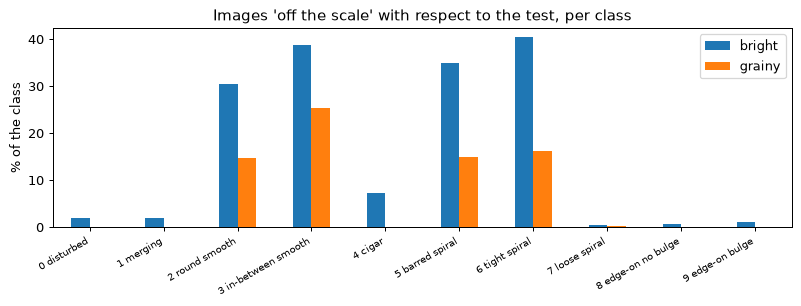

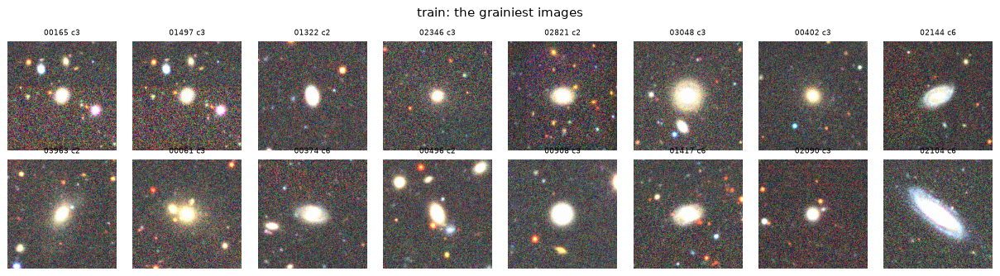

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.5))
per_class.plot.bar(ax=ax)
ax.set_ylabel("% of the class"); ax.set_title("Images 'off the scale' with respect to the test, per class")
plt.xticks(rotation=30, ha="right", fontsize=8); plt.tight_layout(); plt.show()

# examples: the 16 grainiest training images
g = train.nlargest(16, "noise")
show_grid(g.id, [f"{i[6:]} c{int(l)}" for i, l in zip(g.id, g.label)], suptitle="train: the grainiest images")

**Interpretation.** Bright and grainy images are concentrated in a few classes (2, 3, 5, 6) and almost absent from the test: about 97% of the bright images belong to these four classes.

> **What we found later (notebook `01_clean_dataset`).** These images are not just "brightened galaxies": they are **brightened copies of other training images with a swapped label** (2↔3, 5↔6). The "shortcut" is in fact a trap of wrong labels, and the copies are removed during cleaning.

## 5. What kind of shift does the test set have?
Two phenomena to quantify:
- **colour casts:** we use the chromaticity (`chroma_r`, `chroma_g`);
- **blur:** `noise` close to zero.

For colour casts we measure how "far" each image is from the cloud of training points, with the **Mahalanobis distance**: a multi-dimensional z-score that accounts for how much the training set naturally varies in each direction. The threshold is the 99.5th percentile of the training set: by construction only 0.5% of the training set exceeds it.

train: colour cast   0.5%   blurred (noise<=2)   0.6%
test : colour cast   2.4%   blurred (noise<=2)  20.5%


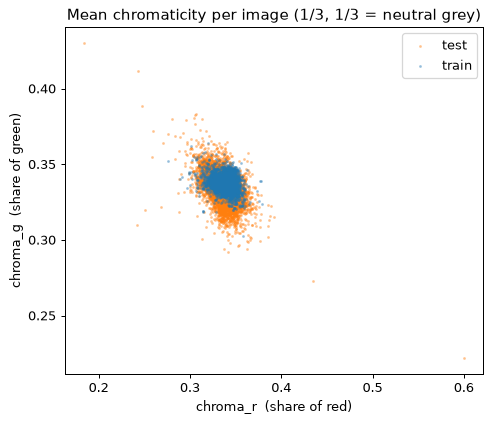

In [10]:
X_tr = train[["chroma_r", "chroma_g"]].to_numpy()
mu, cov_inv = X_tr.mean(0), np.linalg.inv(np.cov(X_tr.T))

def mahal(X):
    d = X - mu
    return np.sqrt(np.einsum("ij,jk,ik->i", d, cov_inv, d))

df["color_dist"] = mahal(df[["chroma_r", "chroma_g"]].to_numpy())
thr_col = np.quantile(df[df.split == "train"].color_dist, 0.995)
df["color_shift"] = df.color_dist > thr_col
df["blurry"] = df["noise"] <= 2
for s in ["train", "test"]:
    d = df[df.split == s]
    print(f"{s:5s}: colour cast {100*d.color_shift.mean():5.1f}%   blurred (noise<=2) {100*d.blurry.mean():5.1f}%")

fig, ax = plt.subplots(figsize=(6, 5))
for s, c in [("test", "tab:orange"), ("train", "tab:blue")]:
    d = df[df.split == s]
    ax.scatter(d.chroma_r, d.chroma_g, s=2, alpha=.3, color=c, label=s)
ax.set_xlabel("chroma_r  (share of red)"); ax.set_ylabel("chroma_g  (share of green)"); ax.legend()
ax.set_title("Mean chromaticity per image (1/3, 1/3 = neutral grey)"); plt.show()

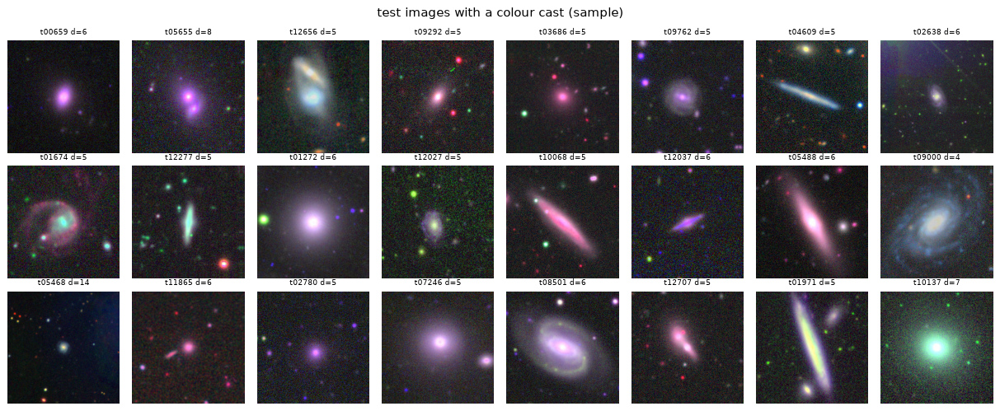

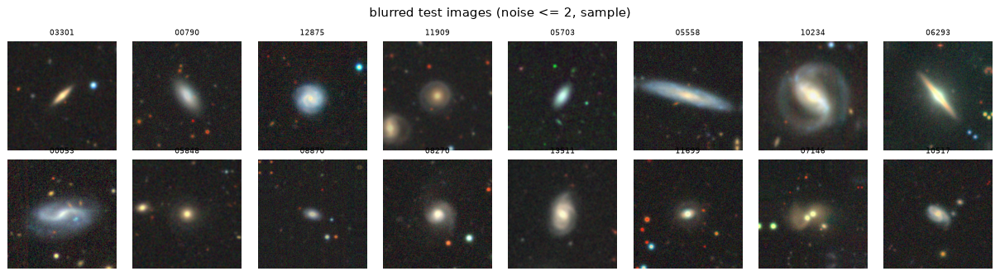

In [11]:
test = df[df.split == "test"]
ex = test[test.color_shift].sample(24, random_state=0)
show_grid(ex.id, [f"t{i[5:]} d={d:.0f}" for i, d in zip(ex.id, ex.color_dist)],
          suptitle="test images with a colour cast (sample)")
ex = test[test.blurry].sample(16, random_state=0)
show_grid(ex.id, suptitle="blurred test images (noise <= 2, sample)")

**What we see.** The colour cast mostly affects **the galaxy**, not the dark background: purple, pink, green, cyan galaxies. The mean chromaticity of the whole image catches only the strongest cases, because the dark sky "dilutes" the signal.

> **Refined later (notebook `02_validation_setup`).** Measuring the colour of the galaxy **core** instead of the whole image, about **18–20% of the test** has altered colours (not the ~2% estimated here). About 20% of the test is blurred, with a **mild** blur.

**Consequence for training.** The model must become robust to hue/saturation changes and to blur, because these cases are almost absent from the training set. Candidate augmentations: `ColorJitter` with a wide hue range, random grayscale, channel shuffle, `GaussianBlur`. Colour remains a useful cue (ellipticals tend to be redder, spirals bluer), so these augmentations should be applied with some probability, not to every image.

## 6. Embeddings from a pretrained model
Pixel statistics only see brightness and colour. To reason about **content** (galaxy shape, presence of the alien) we turn every image into a feature vector with an already-trained network. The model is frozen: no training happens here.

We use **DINOv2 ViT-S/14** (`timm`), a **general-purpose** model: it was trained on natural images and is not specific to astronomy, so it is allowed by the rules. Every image becomes a vector of 384 numbers; similar images give close vectors.

The computation for 19k images takes a few minutes on a GPU; the result is cached.

In [12]:
import torch, timm

emb_file, ids_file = OUT / "emb_dinov2_s.npy", OUT / "emb_dinov2_s_ids.csv"
if emb_file.exists() and ids_file.exists() and (pd.read_csv(ids_file).id.values == df.id.values).all():
    E = np.load(emb_file)
else:
    dev = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
    model = timm.create_model("vit_small_patch14_dinov2.lvd142m", pretrained=True,
                              num_classes=0, img_size=224).eval().to(dev)
    cfg = timm.data.resolve_data_config({}, model=model)
    tf = timm.data.create_transform(**{**cfg, "input_size": (3, 224, 224), "crop_pct": 1.0})
    out = []
    with torch.no_grad():
        for k in tqdm(range(0, len(df), 128)):
            x = torch.stack([tf(C.load_image(i)) for i in df.id[k:k + 128]]).to(dev)
            out.append(model(x).float().cpu().numpy())
    E = np.concatenate(out)
    np.save(emb_file, E); df[["id", "split"]].to_csv(ids_file, index=False)

En = E / np.linalg.norm(E, axis=1, keepdims=True)   # normalised: dot product = cosine similarity
print(E.shape)

  0%|          | 0/149 [00:00<?, ?it/s]

(19064, 384)


## 7. How many images carry the alien?
Idea: every alien image contains the **same object**, so their embeddings are very similar to each other and far from normal galaxies.

1. Start from a few alien images found by looking at the grids (*seeds*).
2. Compute their mean embedding: the "alien prototype".
3. For every image compute the **cosine similarity** with the prototype.

If the idea works, the histogram of the similarity is **bimodal**: normal galaxies with low values and aliens with high values, separated by a gap.

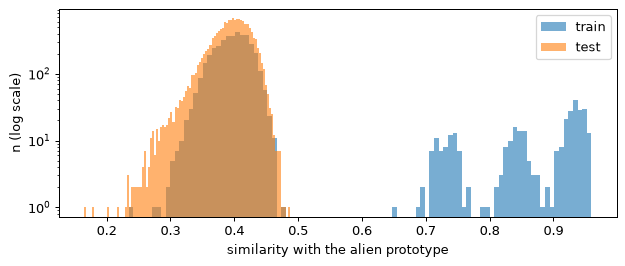

largest gap in the training set: between 0.476 and 0.651
maximum in the test set: 0.487


In [13]:
seeds = ["train_02073", "train_02735", "train_02894", "train_02437", "train_03076",
         "train_00305", "train_00198", "train_03042", "train_03849"]
proto = En[df.id.isin(seeds).to_numpy()].mean(0)
proto /= np.linalg.norm(proto)
df["alien_sim"] = En @ proto

fig, ax = plt.subplots(figsize=(8, 3))
for s, c in [("train", "tab:blue"), ("test", "tab:orange")]:
    ax.hist(df[df.split == s].alien_sim, bins=100, alpha=.6, color=c, label=s, log=True)
ax.set_xlabel("similarity with the alien prototype"); ax.set_ylabel("n (log scale)"); ax.legend(); plt.show()

# the "gap": the highest values among galaxies and the lowest among aliens
tr_sim = np.sort(df[df.split == "train"].alien_sim.values)
gap = np.argmax(np.diff(tr_sim))
print(f"largest gap in the training set: between {tr_sim[gap]:.3f} and {tr_sim[gap+1]:.3f}")
print(f"maximum in the test set: {df[df.split=='test'].alien_sim.max():.3f}")

In [14]:
ALIEN_THR = 0.55          # in the middle of the gap
df["alien"] = df.alien_sim > ALIEN_THR
train = df[df.split == "train"]
print("aliens in train:", train.alien.sum(), f"({100*train.alien.mean():.1f}%)")
print("aliens in test :", df[df.split == "test"].alien.sum())

a = train.groupby("label").alien.agg(n="sum", pct="mean")
a["pct"] = (100 * a.pct).round(1); a.index = [f"{int(c)} {CLASSES[int(c)]}" for c in a.index]
a

aliens in train: 332 (7.7%)
aliens in test : 0


,n,pct
0 disturbed,30,14.1
1 merging,32,9.3
2 round smooth,38,5.1
3 in-between smooth,40,5.8
4 cigar,27,32.5
5 barred spiral,35,6.0
6 tight spiral,24,4.2
7 loose spiral,32,6.7
8 edge-on no bulge,35,12.7
9 edge-on bulge,39,11.0


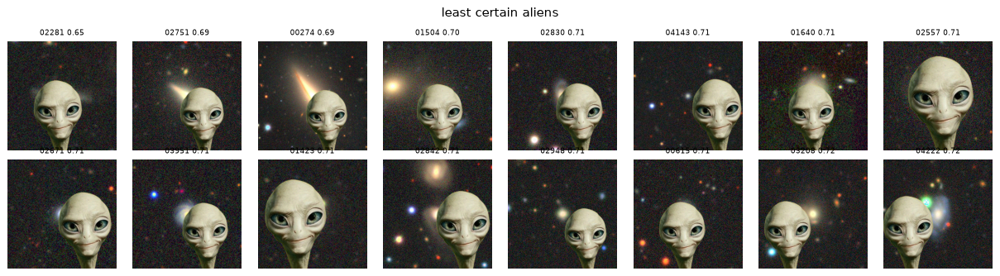

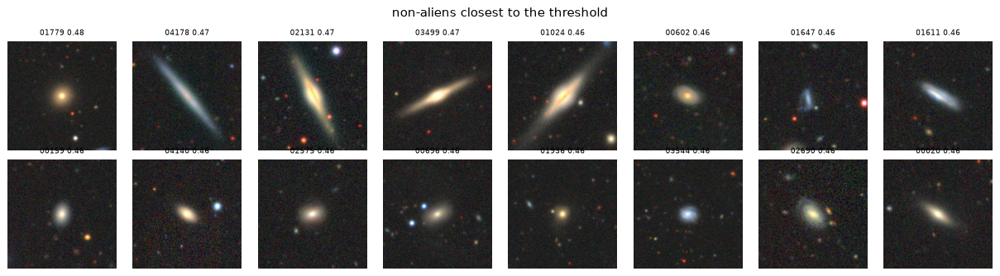

In [15]:
# visual check: the least certain aliens (lowest similarity) and the galaxies closest to the threshold
al = train[train.alien].nsmallest(16, "alien_sim")
show_grid(al.id, [f"{i[6:]} {s:.2f}" for i, s in zip(al.id, al.alien_sim)], suptitle="least certain aliens")
no = train[~train.alien].nlargest(16, "alien_sim")
show_grid(no.id, [f"{i[6:]} {s:.2f}" for i, s in zip(no.id, no.alien_sim)], suptitle="non-aliens closest to the threshold")

**What we found.**
- There is a clear gap in the similarity: the separation is clean (checked by eye on both grids above).
- **There are no aliens in the test.** They are a corruption of the training set only.
- The number of aliens is **roughly constant per class** (~30 each), which is what a random label assignment would produce. For small classes this weighs a lot: for class 4 (*cigar*) they are about a third of the examples.

> **What we found later (notebook `01_clean_dataset`).** Every alien image is a **copy of another training image** with the alien pasted on top and a **random label**. They are removed during cleaning; the original galaxies are already in the training set.

## 8. UMAP: train and test in feature space
**UMAP** projects the 384-dimensional vectors onto 2D, trying to preserve who is close to whom. The axes have no physical meaning and the distances between far-away groups should not be taken literally: what matters is **which points are close together** (= images the model sees as similar).

Two plots with the same projection: one coloured by **split** (train/test) and one by **class** (training set only).

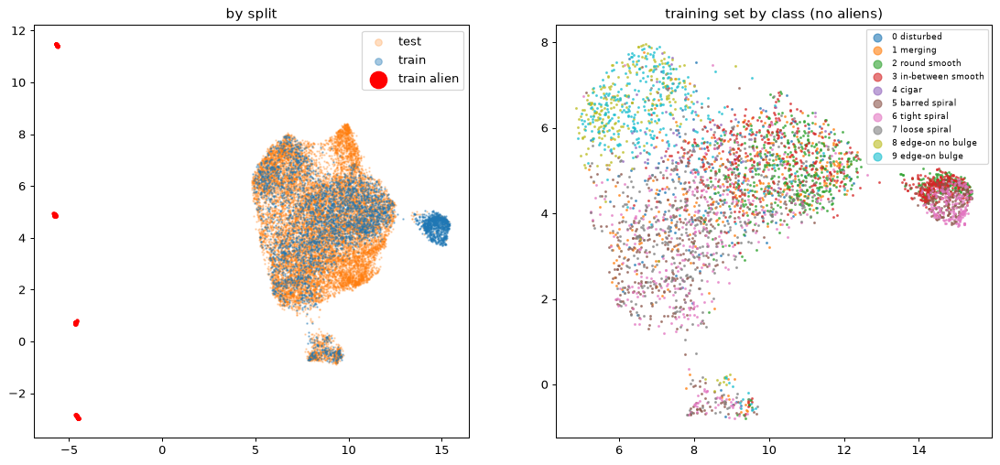

In [16]:
import warnings
import umap
warnings.filterwarnings("ignore", module="umap")   # UMAP prints harmless version warnings
cache = OUT / "umap2d.npy"
if cache.exists():
    U = np.load(cache)
else:
    U = umap.UMAP(n_neighbors=30, min_dist=0.1, metric="cosine", random_state=0).fit_transform(E)
    np.save(cache, U)
df["u1"], df["u2"] = U[:, 0], U[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
te, tr = df[df.split == "test"], df[df.split == "train"]
axes[0].scatter(te.u1, te.u2, s=1, alpha=.25, color="tab:orange", label="test")
axes[0].scatter(tr.u1, tr.u2, s=1, alpha=.4, color="tab:blue", label="train")
axes[0].scatter(tr[tr.alien].u1, tr[tr.alien].u2, s=6, color="red", label="train alien")
axes[0].legend(markerscale=6); axes[0].set_title("by split")
cmap = plt.get_cmap("tab10")
for c in range(10):
    d = tr[(tr.label == c) & ~tr.alien]
    axes[1].scatter(d.u1, d.u2, s=2, alpha=.6, color=cmap(c), label=f"{c} {CLASSES[c]}")
axes[1].legend(markerscale=5, fontsize=7); axes[1].set_title("training set by class (no aliens)")
plt.show()

**How to read it.**
- **Left:**
  - the aliens (red) form completely separate islands;
  - there is an **island of training images only** (blue): the bright and grainy images, which the model "sees" as a different kind of image;
  - some regions contain **test images only** (orange): test images that the training set does not cover well, e.g. blurred or colour-shifted ones.
- **Right:** the training-only island mixes classes 2, 3, 5 and 6, i.e. it is defined by the artefact, not by morphology. Elsewhere the edge-on classes (8, 9) form a group, while the others overlap a lot. The frozen features of a generic model are not enough: we need fine-tuning.

## 9. Adversarial validation: how distinguishable is train from test?
We train a simple classifier (logistic regression on the embeddings) to answer **"does this image come from train or test?"**.

- **AUC ≈ 0.5:** it cannot tell them apart → same distribution, no shift.
- **AUC close to 1:** they are very different, and a validation made of training images is not representative of the test.

The AUC is the probability that, given a random training image and a random test image, the classifier ranks the test image as "more test-like". We use AUC rather than accuracy because the two groups have very different sizes (4k vs 15k).

With cross-validation we also get, for every training image, an **out-of-fold** probability of "looking like test" (from a model that did not see that image).

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

def adversarial(mask):
    # AUC and out-of-fold probability of 'being test' for the rows selected by mask
    X, y = E[mask], (df.split[mask] == "test").astype(int).to_numpy()
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.1, class_weight="balanced"))
    p = cross_val_predict(clf, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=0), method="predict_proba")[:, 1]
    return roc_auc_score(y, p), p

auc_all, p_all = adversarial(np.ones(len(df), bool))
auc_clean, p_clean = adversarial(~df.alien.to_numpy())
print(f"AUC train vs test (everything)   : {auc_all:.3f}")
print(f"AUC train vs test (without aliens): {auc_clean:.3f}")
df.loc[~df.alien, "p_test"] = p_clean

AUC train vs test (everything)   : 0.891
AUC train vs test (without aliens): 0.882


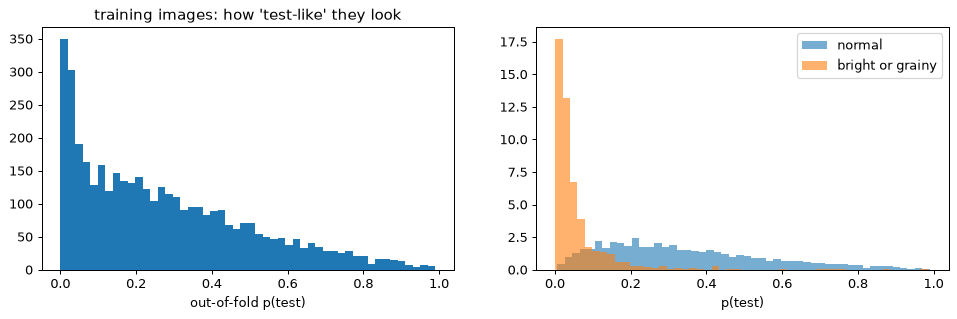

mean p(test) per class:
label
disturbed            0.368
merging              0.347
round smooth         0.226
in-between smooth    0.209
cigar                0.328
barred spiral        0.263
tight spiral         0.214
loose spiral         0.337
edge-on no bulge     0.368
edge-on bulge        0.335


In [18]:
train = df[df.split == "train"]
tr_clean = train[~train.alien]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].hist(tr_clean.p_test, bins=50, color="tab:blue")
axes[0].set_xlabel("out-of-fold p(test)"); axes[0].set_title("training images: how 'test-like' they look")
# do bright/grainy images look less like test?
for name, m in [("normal", ~(tr_clean.bright | tr_clean.grainy)), ("bright or grainy", tr_clean.bright | tr_clean.grainy)]:
    axes[1].hist(tr_clean[m].p_test, bins=50, alpha=.6, density=True, label=name)
axes[1].legend(); axes[1].set_xlabel("p(test)"); plt.show()

print("mean p(test) per class:")
print(tr_clean.groupby("label").p_test.mean().round(3).rename(index=CLASSES).to_string())

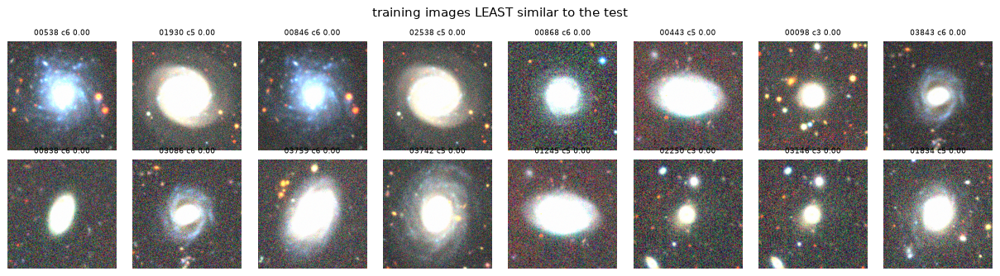

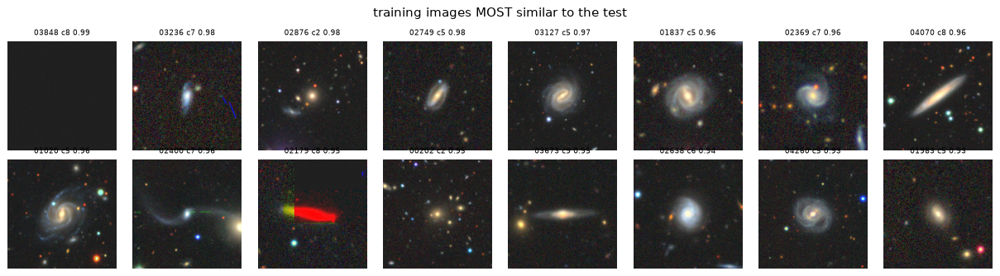

In [19]:
lo = tr_clean.nsmallest(16, "p_test")
show_grid(lo.id, [f"{i[6:]} c{int(l)} {p:.2f}" for i, l, p in zip(lo.id, lo.label, lo.p_test)],
          suptitle="training images LEAST similar to the test")
hi = tr_clean.nlargest(16, "p_test")
show_grid(hi.id, [f"{i[6:]} c{int(l)} {p:.2f}" for i, l, p in zip(hi.id, hi.label, hi.p_test)],
          suptitle="training images MOST similar to the test")

**Interpretation.**
- The AUC (~0.88) says that the shift is **strong**.
- The bright/grainy images are almost all at p(test) ≈ 0: they are the **main reason** why train and test differ. Classes 2, 3, 5, 6 (full of bright images) have the lowest mean p(test).
- The least test-like images are all overexposed and grainy. Among the most test-like there are a few oddities, e.g. `train_03848` (an **empty** grey image, removed during cleaning) and `train_02179` (a red band: a real instrument artefact that also appears in the test).
- A useful check for later: after cleaning, the adversarial AUC should drop, i.e. the training set becomes more similar to the test.

## 10. Linear probe: a first reference F1
Before fine-tuning it is worth knowing how good the features are "as they are". We train a **logistic regression** on the frozen embeddings with a **stratified 5-fold** cross-validation and compute the weighted F1 (the competition metric).

This gives us:
- a **baseline** to beat with fine-tuning;
- the **confusion matrix**, i.e. which classes get confused;
- the images where the model is **very confident about a class different from the label**: candidates for wrong labels.

Aliens are excluded (not representative of the test). Note: at this point the brightened copies are still in the data, so this number is pessimistic (see notebook `01_clean_dataset`).

In [20]:
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

m = ((df.split == "train") & ~df.alien).to_numpy()
X, y = E[m], df.label[m].astype(int).to_numpy()
probe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.05))
P = cross_val_predict(probe, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=0), method="predict_proba")
pred = P.argmax(1)

print(f"weighted F1 (5-fold, no aliens): {f1_score(y, pred, average='weighted'):.3f}")
print(f"accuracy: {(pred == y).mean():.3f}")
print(classification_report(y, pred, target_names=[f"{c} {CLASSES[c]}" for c in range(10)], digits=3))

weighted F1 (5-fold, no aliens): 0.564
accuracy: 0.569
                     precision    recall  f1-score   support

        0 disturbed      0.295     0.169     0.215       183
          1 merging      0.543     0.559     0.551       313
     2 round smooth      0.575     0.639     0.605       706
3 in-between smooth      0.572     0.591     0.581       645
            4 cigar      0.541     0.357     0.430        56
    5 barred spiral      0.537     0.503     0.519       549
     6 tight spiral      0.505     0.490     0.497       541
     7 loose spiral      0.441     0.461     0.451       445
 8 edge-on no bulge      0.816     0.826     0.821       241
    9 edge-on bulge      0.811     0.855     0.833       317

           accuracy                          0.569      3996
          macro avg      0.564     0.545     0.550      3996
       weighted avg      0.562     0.569     0.564      3996



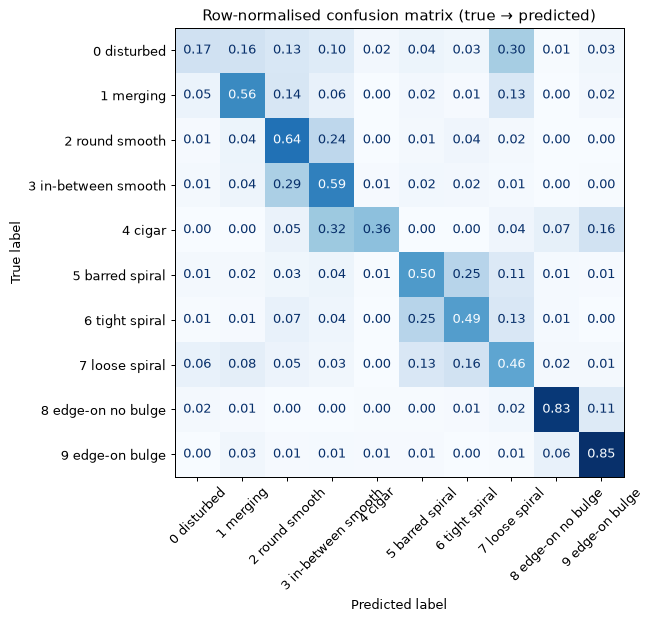

In [21]:
cm = confusion_matrix(y, pred, normalize="true")       # each row sums to 1: where the examples of that class end up
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=[f"{c} {CLASSES[c]}" for c in range(10)]).plot(
    ax=ax, values_format=".2f", cmap="Blues", colorbar=False, xticks_rotation=45)
ax.set_title("Row-normalised confusion matrix (true → predicted)")
plt.tight_layout(); plt.show()

**How to read it.** The diagonal is the share of each class recognised correctly. High values off the diagonal are the **confused pairs**: smooth 2↔3, spirals 5/6/7, and *disturbed* (0) mistaken for *loose spiral* (7). Part of the 2↔3 and 5↔6 confusion is caused by the relabelled copies.

suspicious labels: 86 (2.2% of the training set without aliens)
predicted  0  1  2  3  5  6  7  8  9
label                               
0          0  2  3  4  1  0  4  0  2
1          0  0  0  0  1  2  2  1  0
2          1  1  0  1  0  0  0  0  0
3          0  2  4  0  0  0  0  0  0
4          0  0  0  1  0  0  0  1  1
5          0  4  0  0  0  6  2  3  0
6          1  0  2  1  2  0  4  1  0
7          1  8  0  1  7  0  0  1  1
8          0  1  0  0  0  0  0  0  2
9          0  0  0  0  1  0  0  3  0


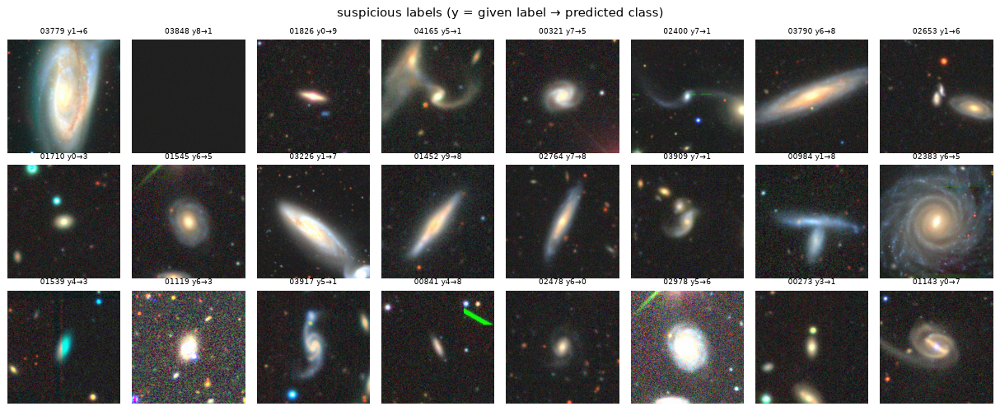

In [22]:
# suspicious labels: the model gives a very low probability to the given label
# and a high probability to another class
sub = df[m].copy()
sub["p_label"] = P[np.arange(len(y)), y]
sub["pred"], sub["p_pred"] = pred, P.max(1)
sus = sub[(sub.p_label < 0.05) & (sub.p_pred > 0.8)].sort_values("p_label")
print("suspicious labels:", len(sus), f"({100*len(sus)/len(sub):.1f}% of the training set without aliens)")
print(pd.crosstab(sus.label.astype(int), sus.pred, rownames=["label"], colnames=["predicted"]))
s = sus.head(24)
show_grid(s.id, [f"{i[6:]} y{int(l)}→{p}" for i, l, p in zip(s.id, s.label, s.pred)],
          suptitle="suspicious labels (y = given label → predicted class)")

**Careful.** A "suspicious" label is not necessarily wrong: it can also be a limit of the linear probe. The final list of suspicious labels is computed in notebook `01_clean_dataset`, on the cleaned data.

## 11. Exact duplicates
We check whether some images have exactly the same pixels (MD5 hash of the pixel array), inside the training set or between train and test.

Near-duplicates (the same scene, modified) are **not** detected here: they are found in notebook `01_clean_dataset` by comparing the **star pattern** in the background, which is unaffected by brightening.

In [23]:
df["md5"] = [hashlib.md5(load(i).tobytes()).hexdigest() for i in tqdm(df.id)]
dup = df[df.duplicated("md5", keep=False)].sort_values("md5")
print("images involved in exact duplicates:", len(dup))
print(dup.groupby("md5").agg(ids=("id", list), labels=("label", list)).head(10).to_string())

  0%|          | 0/19064 [00:00<?, ?it/s]

images involved in exact duplicates: 0
Empty DataFrame
Columns: [ids, labels]
Index: []


## 12. Save the metadata
The computed columns (alien, bright, grainy, blurry, p(test), ...) are needed by the next notebooks. We save them in `outputs/meta.csv`.

In [24]:
meta = df[["id", "split", "label", "alien", "bright", "grainy", "blurry", "color_shift", "p_test",
           "mean", "noise", "sat", "chroma_r", "chroma_g"]]
meta.to_csv(OUT / "meta.csv", index=False)
meta.head()

,id,split,label,alien,bright,grainy,blurry,color_shift,p_test,mean,noise,sat,chroma_r,chroma_g
0,train_00000,train,3.0,False,False,False,False,False,0.242009,39.298473,4.0,130.782715,0.340632,0.338949
1,train_00001,train,2.0,False,False,False,False,False,0.180957,35.312878,5.0,118.034348,0.334237,0.339282
2,train_00002,train,9.0,False,False,False,False,False,0.342587,35.570026,6.0,127.762497,0.342730,0.333103
3,train_00003,train,1.0,False,False,False,False,False,0.216234,39.499146,6.0,125.988846,0.338267,0.338078
4,train_00004,train,9.0,False,False,False,False,False,0.062556,35.378948,7.0,125.989914,0.342420,0.335273


## Summary

| Finding | Numbers | What it implies |
|---|---|---|
| Imbalanced classes | class 4 (*cigar*) = 1.9% | **stratified** K-fold; watch the F1 of class 4 |
| Pasted **aliens** | 332 in train (7.7%), **0 in test**, ~30 per class | they are relabelled copies → removed in `01_clean_dataset` |
| **Bright and grainy** images | ~22% of train, ~1% of test; almost only classes 2, 3, 5, 6 | they are brightened copies with swapped labels (2↔3, 5↔6) → removed in `01_clean_dataset` |
| Test: **blur** | ~20% of test, ~0.6% of train | blur augmentation; measured precisely in `02_validation_setup` |
| Test: **colour casts** | ~2% with the whole-image measure, **~20%** with the galaxy-core measure (`02`) | hue / saturation / channel augmentations; do not rely too much on colour |
| Overall shift | adversarial AUC ≈ 0.88 | validation on training images overestimates: also use a test-like (shifted) validation |
| Linear probe baseline (frozen DINOv2-S) | weighted F1 ≈ 0.56 here (≈ 0.63 after cleaning) | fine-tuning must clearly beat it |
| Confused classes | smooth 2↔3, spirals 5/6/7, *disturbed* 0 | where more capacity and resolution are needed |
| Exact duplicates | none | — |
| Empty image | `train_03848` | removed |

**Next notebook:** `01_clean_dataset`, which finds the copies and produces the clean training set.